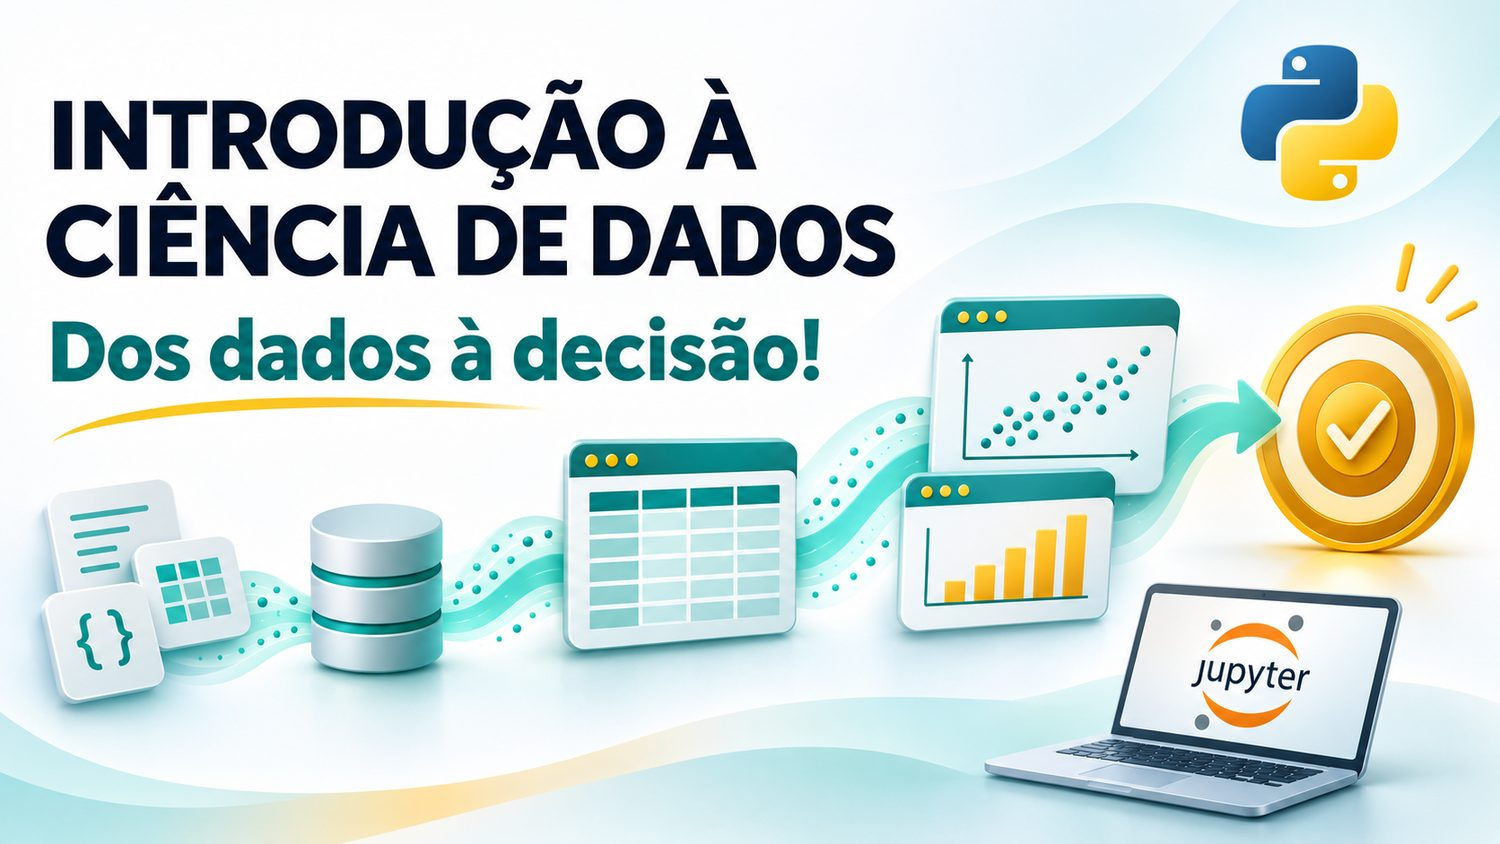

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_aprendizagem_nao_supervisionada/01_KMeans.ipynb)

# Capítulo 1 – Agrupar sem rótulos: K-Means

Nos módulos 4 e 5 havia sempre um **alvo**: uma coluna com a resposta certa, que o modelo aprendia a prever. Neste módulo essa coluna não existe. Temos só os atributos, e a pergunta passa a ser: **há grupos nestes dados?** Chama-se a isto **aprendizagem não supervisionada**. Este capítulo apresenta o algoritmo de agrupamento mais usado, o K-Means, construído de raiz em NumPy.

> **Objetivos:** distinguir aprendizagem supervisionada de não supervisionada; explicar os dois passos do K-Means; implementá-lo em NumPy; medir a qualidade de um agrupamento com a inércia; perceber o efeito da inicialização e da escala; descrever os grupos encontrados e dar-lhes nome; conhecer as limitações do método.

**Pré-requisitos:** os capítulos 2 do módulo 5 (distâncias) e 4 do módulo 4 (escalas). As operações com arrays estão em [NumPy](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_1_introducao/22_NumPy.ipynb); há outra abordagem ao mesmo problema em [Otimização e grupos](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_08_Otimizacao_Grupos.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## Aprender sem resposta certa

| | Supervisionada (módulos 4 e 5) | Não supervisionada (este módulo) |
| --- | --- | --- |
| Os dados têm | Atributos e um alvo | Só atributos |
| Pergunta | Qual é o valor do alvo para um caso novo? | Que estrutura há nos dados? |
| Tarefas | Classificação, regressão | Agrupamento (*clustering*), redução de dimensão |
| Avalia-se | Comparando a previsão com a resposta | Sem resposta certa: pela coerência e pela utilidade |
| Exemplo | Esta entrega vai atrasar? | Que tipos de clientes temos? |

A última linha da avaliação é a grande diferença. Sem alvo, não há exatidão nem erro médio. Dois analistas podem chegar a agrupamentos diferentes e ambos defensáveis. O capítulo 2 é dedicado a esse problema.

## O caso deste módulo: quem usa a aplicação?

Uma aplicação de aprendizagem de línguas tem milhares de utilizadores e envia a todos as mesmas notificações e as mesmas ofertas. A equipa suspeita de que há **maneiras muito diferentes de usar a aplicação** e quer conhecê-las, para adaptar a comunicação. Ninguém sabe à partida quantos tipos há, nem quais são.

Os dados são sintéticos: uma linha por utilizador, com o seu comportamento nas últimas semanas.

In [2]:
def gerar_utilizadores(n=3000, semente=53, com_perfil=False):
    """Gera utilizadores de uma aplicação fictícia de aprendizagem de línguas (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    perfil = rng.choice(4, n, p=[0.34, 0.22, 0.30, 0.14])
    # por perfil: sessões por semana, minutos por sessão, dias seguidos, % à noite, exercícios de fala, % de erros
    centros = np.array([[9.5, 6.0, 38, 30, 2.0, 22],
                        [2.2, 34.0, 3, 55, 6.0, 17],
                        [1.3, 7.0, 1, 45, 0.6, 31],
                        [7.5, 27.0, 55, 40, 14.0, 12]])
    desvios = np.array([[2.2, 1.8, 22, 16, 1.6, 6], [0.8, 8.0, 2.5, 18, 3.0, 5], [0.7, 3.0, 1.2, 20, 0.7, 8], [2.0, 7.0, 30, 17, 5.0, 4]])
    v = rng.normal(centros[perfil], desvios[perfil])
    sessoes = v[:, 0].clip(0.2, 21).round(1)
    minutos = v[:, 1].clip(2, 70).round(1)
    licoes = (sessoes * minutos / 5.5 * rng.normal(1, 0.12, n)).clip(0.2).round(1)
    tabela = pd.DataFrame({"sessoes_semana": sessoes, "minutos_sessao": minutos, "licoes_semana": licoes,
                           "dias_seguidos": v[:, 2].clip(0, 200).round(), "pct_noite": v[:, 3].clip(0, 100).round(),
                           "exercicios_fala": v[:, 4].clip(0, 40).round(1), "pct_erros": v[:, 5].clip(2, 60).round(1),
                           "meses_na_app": rng.gamma(1.8, 5, n).clip(0.5, 48).round(1)})
    tabela["premium"] = rng.random(n) < np.array([0.12, 0.25, 0.03, 0.55])[perfil]
    if com_perfil:                                   # só para verificação: num caso real esta coluna não existe
        tabela["perfil_verdadeiro"] = perfil
    return tabela


utilizadores = gerar_utilizadores()
utilizadores.head()

,sessoes_semana,minutos_sessao,licoes_semana,dias_seguidos,pct_noite,exercicios_fala,pct_erros,meses_na_app,premium
0,10.3,9.2,11.2,25.0,49.0,0.9,15.8,17.9,False
1,1.4,7.0,1.7,0.0,62.0,0.0,32.3,3.2,False
2,9.5,5.1,8.7,52.0,58.0,3.7,28.6,22.9,False
3,2.7,25.2,13.0,29.0,52.0,13.3,13.1,8.4,False
4,11.7,8.2,15.5,39.0,14.0,0.0,21.7,16.4,False


| Coluna | Significado |
| --- | --- |
| `sessoes_semana` | Número médio de sessões por semana |
| `minutos_sessao` | Duração média de uma sessão, em minutos |
| `licoes_semana` | Lições concluídas por semana |
| `dias_seguidos` | Dias consecutivos de utilização (a «sequência» atual) |
| `pct_noite` | Percentagem das sessões feitas depois das 20h |
| `exercicios_fala` | Exercícios de pronúncia por semana |
| `pct_erros` | Percentagem de respostas erradas |
| `meses_na_app` | Há quantos meses usa a aplicação |
| `premium` | Se paga a versão completa |

Para ver o algoritmo a funcionar, começamos com duas colunas, que podemos desenhar.

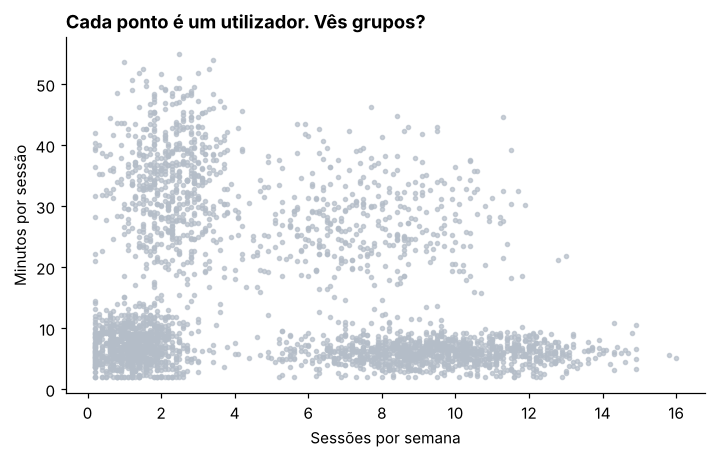

In [3]:
dois = ["sessoes_semana", "minutos_sessao"]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(utilizadores[dois[0]], utilizadores[dois[1]], s=7, color=CINZA, alpha=0.7)
ax.set_xlabel("Sessões por semana")
ax.set_ylabel("Minutos por sessão")
ax.set_title("Cada ponto é um utilizador. Vês grupos?")
plt.show()

A olho, notam-se zonas mais densas: muita gente com poucas sessões curtas, um grupo com sessões longas e raras, outro com muitas sessões curtas. O K-Means vai tentar encontrar essas zonas sem que lhe digamos onde estão. Só lhe dizemos **quantos grupos** queremos: é o **k** do nome.

## O algoritmo

Cada grupo é representado por um ponto, o **centroide**: a média dos membros do grupo. O K-Means alterna dois passos até nada mudar.

1. **Atribuir:** cada utilizador vai para o grupo do centroide mais próximo.
2. **Atualizar:** cada centroide passa para a média dos utilizadores que lhe foram atribuídos.

Para começar, escolhem-se k utilizadores ao acaso para servirem de centroides iniciais.

Como o algoritmo mede distâncias, as colunas têm de estar na **mesma escala**, tal como no KNN. Aqui não há treino e teste: usamos todos os dados para normalizar.

In [4]:
X = utilizadores[dois].to_numpy()
Z = (X - X.mean(axis=0)) / X.std(axis=0)                 # pontuações z


def atribuir(Z, centroides):
    """Passo 1: o índice do centroide mais próximo de cada ponto."""
    distancias = np.sqrt(((Z[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2))    # tabela pontos × centroides
    return distancias.argmin(axis=1)


def atualizar(Z, grupos, k):
    """Passo 2: cada centroide passa a ser a média dos pontos do seu grupo."""
    return np.array([Z[grupos == j].mean(axis=0) for j in range(k)])


def inercia(Z, grupos, centroides):
    """Soma dos quadrados das distâncias de cada ponto ao centroide do seu grupo."""
    return float(((Z - centroides[grupos]) ** 2).sum())

A expressão `Z[:, None, :] - centroides[None, :, :]` calcula de uma vez as diferenças entre **todos** os pontos e **todos** os centroides (o *broadcasting* do NumPy), sem ciclos.

Vamos seguir as primeiras iterações com k = 4.

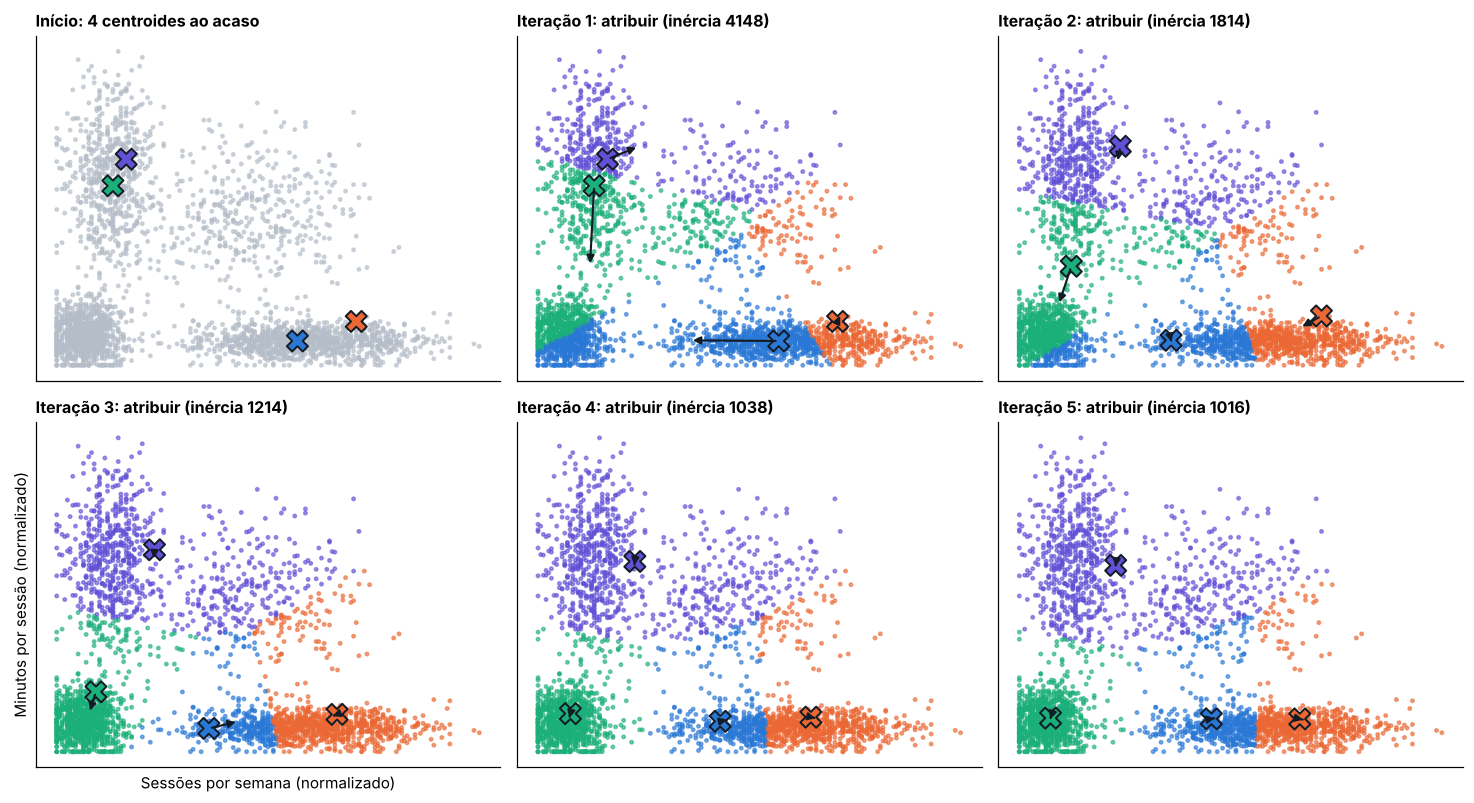

In [5]:
CORES = [AZUL, LARANJA, VERDE, VIOLETA, AVISO, MAU]
k = 4
rng = np.random.default_rng(3)
centroides = Z[rng.choice(len(Z), k, replace=False)]      # k utilizadores ao acaso


def desenhar(ax, Z, grupos, centroides, titulo):
    cores = [CINZA] * len(Z) if grupos is None else [CORES[g] for g in grupos]
    ax.scatter(Z[:, 0], Z[:, 1], s=5, color=cores, alpha=0.6)
    ax.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=190, color=CORES[:len(centroides)], edgecolor=TINTA, linewidth=1.3, zorder=3)
    ax.set_title(titulo, fontsize=10.5)
    ax.set_xticks([])
    ax.set_yticks([])


fig, eixos = plt.subplots(2, 3, figsize=(13.5, 7.4))
desenhar(eixos[0, 0], Z, None, centroides, "Início: 4 centroides ao acaso")
historico = []
for iteracao, ax in zip(range(1, 6), eixos.ravel()[1:]):
    grupos = atribuir(Z, centroides)
    historico.append(inercia(Z, grupos, centroides))
    desenhar(ax, Z, grupos, centroides, f"Iteração {iteracao}: atribuir (inércia {historico[-1]:.0f})")
    novos = atualizar(Z, grupos, k)
    for antigo, novo in zip(centroides, novos):
        ax.annotate("", novo, antigo, arrowprops={"arrowstyle": "-|>", "color": TINTA, "lw": 1.4})
    centroides = novos
eixos[1, 0].set_xlabel("Sessões por semana (normalizado)")
eixos[1, 0].set_ylabel("Minutos por sessão (normalizado)")
plt.tight_layout()
plt.show()

Em cada painel, os pontos têm a cor do centroide mais próximo (passo 1) e as setas mostram para onde cada centroide se vai mover (passo 2). Nas primeiras iterações os centroides deslocam-se muito; depois as setas encolhem até desaparecerem. Quando nenhum ponto muda de grupo, o algoritmo **convergiu**.

### A inércia: o que o K-Means minimiza

A **inércia** é a soma dos quadrados das distâncias de cada ponto ao centroide do seu grupo. Mede quão **compactos** são os grupos: quanto menor, mais perto estão os membros do seu centro.

Cada um dos dois passos só pode **baixar** a inércia (ou mantê-la). Por isso o algoritmo acaba sempre por parar.

Juntamos tudo numa função:

In [6]:
def kmeans(Z, k, semente=0, max_iteracoes=100):
    """K-Means: devolve os grupos, os centroides e a inércia em cada iteração."""
    rng = np.random.default_rng(semente)
    centroides = Z[rng.choice(len(Z), k, replace=False)]
    historico = []
    for _ in range(max_iteracoes):
        grupos = atribuir(Z, centroides)
        historico.append(inercia(Z, grupos, centroides))
        novos = atualizar(Z, grupos, k)
        if np.allclose(novos, centroides):                # os centroides já não se movem
            break
        centroides = novos
    return grupos, centroides, historico


grupos, centroides, historico = kmeans(Z, 4, semente=3)
print(f"Convergiu em {len(historico)} iterações. Inércia: {historico[0]:.0f} → {historico[-1]:.0f}")
print("Tamanho dos grupos:", np.bincount(grupos))

Convergiu em 17 iterações. Inércia: 4148 → 1003
Tamanho dos grupos: [691 517 933 859]


## A inicialização conta

O K-Means encontra **um** mínimo da inércia, que depende de onde começou. Não é garantido que seja o melhor.

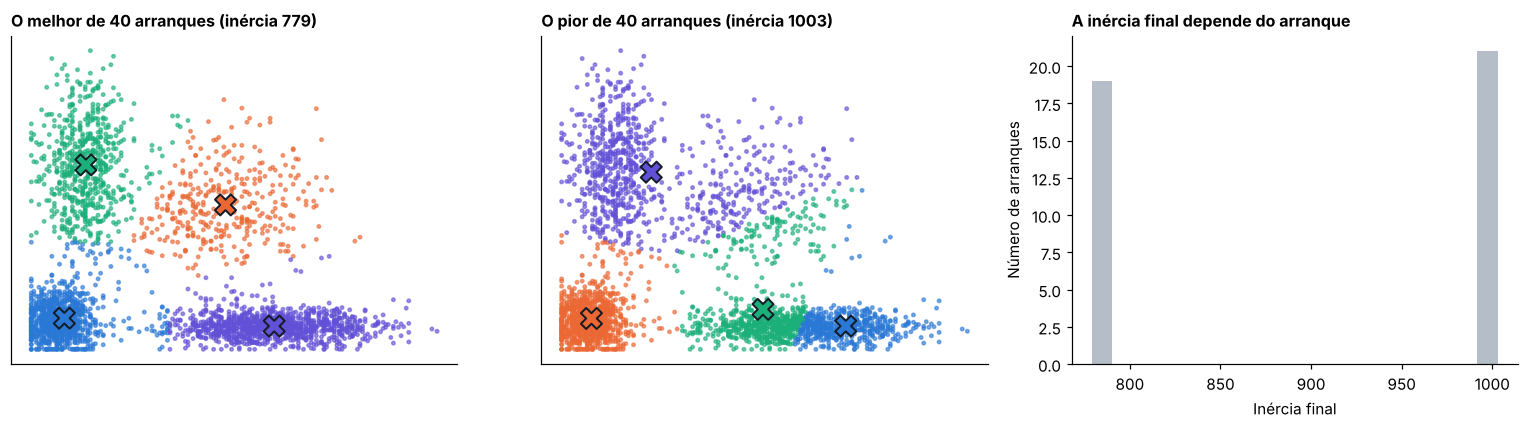

In [7]:
resultados = [kmeans(Z, 4, semente=s) for s in range(40)]
inercias = np.array([r[2][-1] for r in resultados])
melhor, pior = resultados[int(inercias.argmin())], resultados[int(inercias.argmax())]

fig, eixos = plt.subplots(1, 3, figsize=(14, 4))
desenhar(eixos[0], Z, melhor[0], melhor[1], f"O melhor de 40 arranques (inércia {inercias.min():.0f})")
desenhar(eixos[1], Z, pior[0], pior[1], f"O pior de 40 arranques (inércia {inercias.max():.0f})")
eixos[2].hist(inercias, bins=20, color=CINZA)
eixos[2].set_xlabel("Inércia final")
eixos[2].set_ylabel("Número de arranques")
eixos[2].set_title("A inércia final depende do arranque", fontsize=10.5)
plt.tight_layout()
plt.show()

Cerca de metade dos arranques acaba numa solução pior (foi o caso do que seguimos passo a passo): por exemplo, com dois centroides a dividir entre si um grupo que devia ser um só, e um único centroide a cobrir dois grupos. O algoritmo ficou preso num **mínimo local**: nenhum dos dois passos consegue melhorar, apesar de existir uma solução melhor.

Há duas defesas, e o scikit-learn usa ambas:

- **repetir** o algoritmo com vários arranques e ficar com o de menor inércia (o parâmetro `n_init`);
- **escolher melhor os centroides iniciais**: o método *k-means++* escolhe-os afastados uns dos outros, o que evita a maior parte dos maus arranques.

In [8]:
from sklearn.cluster import KMeans

oficial = KMeans(n_clusters=4, n_init=10, random_state=0).fit(Z)
print(f"scikit-learn: inércia {oficial.inertia_:.1f} | o nosso melhor arranque: {inercias.min():.1f}")
print("Tamanhos (scikit-learn):", np.sort(np.bincount(oficial.labels_)), "| (nosso):", np.sort(np.bincount(melhor[0])))

scikit-learn: inércia 779.1 | o nosso melhor arranque: 779.1
Tamanhos (scikit-learn): [ 352  610  968 1070] | (nosso): [ 352  610  968 1070]


A nossa implementação e a do scikit-learn chegam à mesma solução. Os **números** dos grupos (0, 1, 2, 3) podem não coincidir: são etiquetas arbitrárias, e o grupo «2» de uma execução pode ser o «0» de outra. O que interessa é quem fica com quem.

## Sem normalizar, manda a coluna maior

Passamos a usar todas as colunas numéricas. Antes, uma experiência: o que acontece se nos esquecermos da normalização?

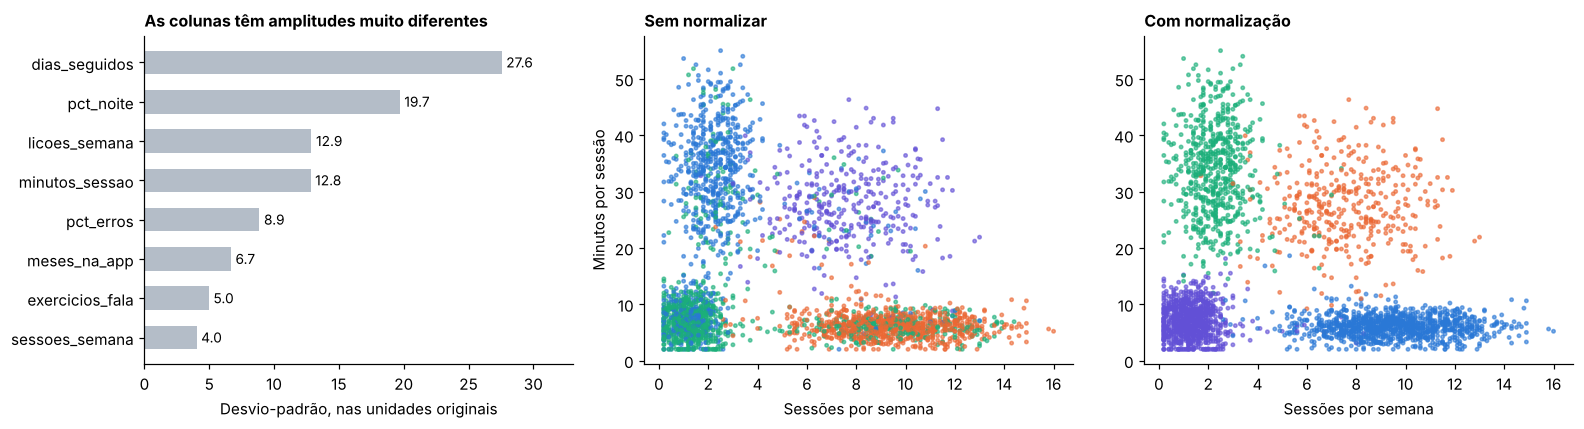

In [9]:
from sklearn.preprocessing import StandardScaler

numericas = [c for c in utilizadores.columns if c != "premium"]
escala = StandardScaler().fit(utilizadores[numericas])
Z8 = escala.transform(utilizadores[numericas])
sem_escala = KMeans(4, n_init=10, random_state=0).fit(utilizadores[numericas])
com_escala = KMeans(4, n_init=10, random_state=0).fit(Z8)

amplitude = utilizadores[numericas].std().sort_values(ascending=False)
fig, eixos = plt.subplots(1, 3, figsize=(14.5, 4))
barras = eixos[0].barh(amplitude.index, amplitude, color=CINZA, height=0.6)
eixos[0].bar_label(barras, fmt="%.1f", padding=3, fontsize=9)
eixos[0].invert_yaxis()
eixos[0].set_xlim(0, amplitude.max() * 1.2)
eixos[0].set_xlabel("Desvio-padrão, nas unidades originais")
eixos[0].set_title("As colunas têm amplitudes muito diferentes", fontsize=10.5)
for ax, modelo, titulo in [(eixos[1], sem_escala, "Sem normalizar"), (eixos[2], com_escala, "Com normalização")]:
    ax.scatter(utilizadores["sessoes_semana"], utilizadores["minutos_sessao"], s=5, color=[CORES[g] for g in modelo.labels_], alpha=0.6)
    ax.set_xlabel("Sessões por semana")
    ax.set_title(titulo, fontsize=10.5)
eixos[1].set_ylabel("Minutos por sessão")
plt.tight_layout()
plt.show()

Sem normalização, as colunas com números maiores (os dias seguidos, a percentagem de sessões à noite) dominam a distância. Os grupos encontrados misturam, no plano das sessões e dos minutos, utilizadores com comportamentos claramente diferentes. Com normalização, todas as colunas contam o mesmo e os grupos voltam a fazer sentido.

> **Num agrupamento, a escolha das colunas e da escala é a decisão mais importante.** Define o que significa «parecido», e não há um alvo para dizer se a escolha foi boa.

## Descrever os grupos

O resultado de um K-Means é uma coluna nova com o número do grupo. Sozinha, não diz nada. O trabalho útil é **descrever** cada grupo e perceber se a descrição faz sentido.

In [10]:
utilizadores["grupo"] = com_escala.labels_
perfil = utilizadores.groupby("grupo")[numericas].mean()
perfil.insert(0, "utilizadores", utilizadores["grupo"].value_counts().sort_index())
perfil.round(1)

,utilizadores,sessoes_semana,minutos_sessao,licoes_semana,dias_seguidos,pct_noite,exercicios_fala,pct_erros,meses_na_app
grupo,,,,,,,,,
0,1081,9.5,6.0,10.4,39.4,31.1,2.1,22.1,8.7
1,388,7.6,27.4,38.2,58.4,40.7,14.3,12.0,9.3
2,630,2.3,33.7,13.9,3.4,54.9,6.0,17.3,8.6
3,901,1.4,7.1,1.7,1.3,44.5,0.7,30.8,9.3


A tabela de médias, nas unidades originais, é a primeira leitura. Com muitas colunas é mais fácil ver as diferenças num mapa: para cada grupo, quanto a sua média se afasta da média geral, em desvios-padrão.

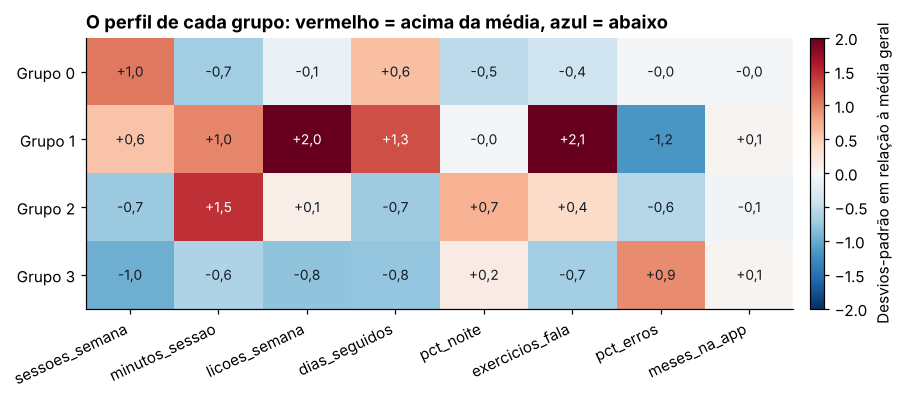

In [11]:
centros = pd.DataFrame(com_escala.cluster_centers_, columns=numericas)
fig, ax = plt.subplots(figsize=(10, 3.2))
imagem = ax.imshow(centros, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
for i in range(centros.shape[0]):
    for j in range(centros.shape[1]):
        valor = centros.iloc[i, j]
        ax.text(j, i, f"{valor:+.1f}".replace(".", ","), ha="center", va="center", fontsize=9, color="white" if abs(valor) > 1.2 else TINTA)
ax.set_xticks(range(len(numericas)), numericas, rotation=25, ha="right")
ax.set_yticks(range(4), [f"Grupo {g}" for g in range(4)])
ax.grid(False)
fig.colorbar(imagem, ax=ax, label="Desvios-padrão em relação à média geral", pad=0.02)
ax.set_title("O perfil de cada grupo: vermelho = acima da média, azul = abaixo")
plt.show()

Lendo linha a linha, cada grupo ganha uma personalidade. Os números dos grupos são arbitrários; os perfis são estes:

| Perfil | Como se reconhece | Nome possível |
| --- | --- | --- |
| Muitas sessões curtas, sequência longa | `sessoes_semana` e `dias_seguidos` altos, `minutos_sessao` baixo | **Os do hábito diário** |
| Poucas sessões longas | `minutos_sessao` alto, `sessoes_semana` e `dias_seguidos` baixos | **Os de fim de semana** |
| Pouco de tudo, muitos erros | quase tudo abaixo da média, `pct_erros` alto | **Os que estão a desistir** |
| Muito de tudo, muita fala, poucos erros | `licoes_semana` e `exercicios_fala` muito altos | **Os intensivos** |

**Dar nome aos grupos** obriga a perceber o que os distingue, e é com os nomes que o resultado se comunica. Repara que `meses_na_app` fica perto de zero em todos os grupos: a antiguidade não distingue estes perfis.

### Uma verificação com uma coluna que ficou de fora

A coluna `premium` não entrou no agrupamento. Se os grupos captam algo real, é provável que difiram também noutras coisas.

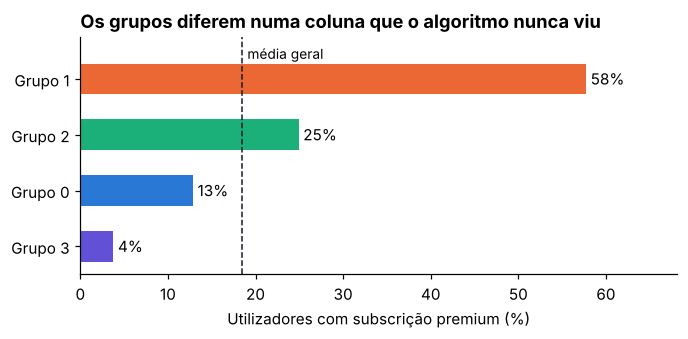

In [12]:
taxa = utilizadores.groupby("grupo")["premium"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 2.8))
barras = ax.barh([f"Grupo {g}" for g in taxa.index], taxa * 100, color=[CORES[g] for g in taxa.index], height=0.55)
ax.bar_label(barras, fmt="%.0f%%", padding=3)
ax.axvline(utilizadores["premium"].mean() * 100, color=TINTA, ls="--", lw=1)
ax.text(utilizadores["premium"].mean() * 100 + 0.6, 3.45, "média geral", fontsize=9, va="center")
ax.set_ylim(-0.5, 3.75)
ax.set_xlim(0, taxa.max() * 118)
ax.set_xlabel("Utilizadores com subscrição premium (%)")
ax.set_title("Os grupos diferem numa coluna que o algoritmo nunca viu")
plt.show()

A taxa de subscrição varia muito de grupo para grupo. O agrupamento foi feito só com o comportamento, e separa utilizadores que também são diferentes do ponto de vista do negócio. É um sinal de que os grupos são **úteis**, que é o critério que mais importa.

## Um utilizador novo

Para saber a que grupo pertence um utilizador novo, basta o passo 1 do algoritmo: normalizá-lo com a mesma escala e procurar o centroide mais próximo.

In [13]:
novo = pd.DataFrame([{"sessoes_semana": 10, "minutos_sessao": 5, "licoes_semana": 9, "dias_seguidos": 60, "pct_noite": 20,
                      "exercicios_fala": 1, "pct_erros": 25, "meses_na_app": 7}])
print("Grupo do utilizador novo:", int(com_escala.predict(escala.transform(novo))[0]))

Grupo do utilizador novo: 0


## Limitações

O K-Means é rápido e simples, e tem pressupostos que convém conhecer.

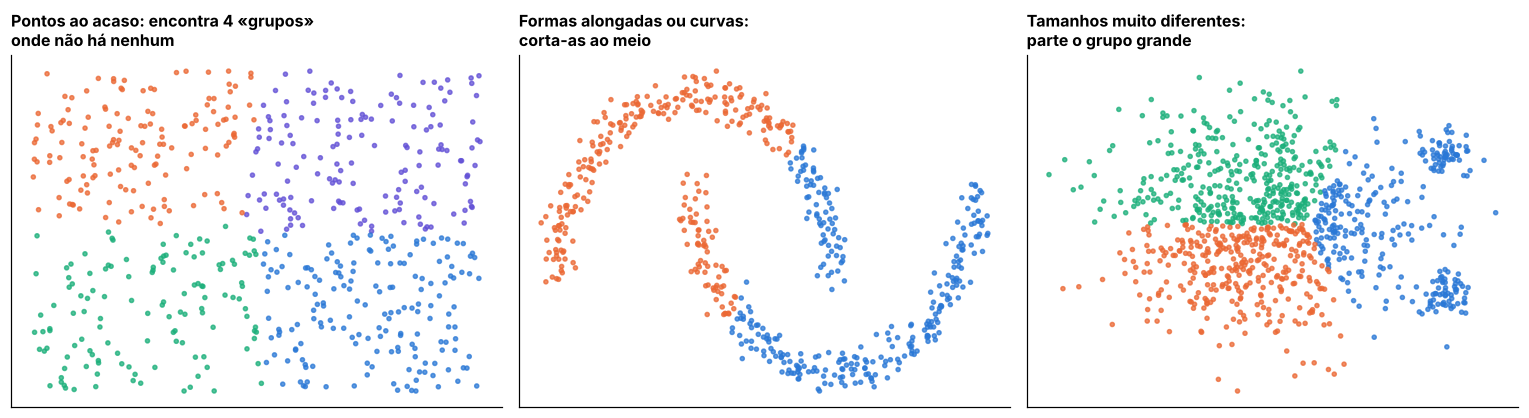

In [14]:
from sklearn.datasets import make_blobs, make_moons

rng = np.random.default_rng(0)
ao_acaso = rng.random((600, 2))
luas, _ = make_moons(600, noise=0.06, random_state=0)
desiguais, _ = make_blobs(n_samples=[900, 60, 60], centers=[[0, 0], [4.2, 2.2], [4.2, -2.2]], cluster_std=[1.7, 0.35, 0.35], random_state=0)

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, dados, k, titulo in [(eixos[0], ao_acaso, 4, "Pontos ao acaso: encontra 4 «grupos»\nonde não há nenhum"),
                             (eixos[1], luas, 2, "Formas alongadas ou curvas:\ncorta-as ao meio"),
                             (eixos[2], desiguais, 3, "Tamanhos muito diferentes:\nparte o grupo grande")]:
    rotulos = KMeans(k, n_init=10, random_state=0).fit_predict(dados)
    ax.scatter(dados[:, 0], dados[:, 1], s=7, color=[CORES[g] for g in rotulos], alpha=0.75)
    ax.set_title(titulo, fontsize=10.5)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

| Limitação | Porquê | O que fazer |
| --- | --- | --- |
| **Devolve sempre k grupos**, mesmo que não existam | Minimizar a inércia é sempre possível | Avaliar se os grupos são reais (capítulo 2) |
| É preciso **escolher k** à partida | Faz parte da definição do algoritmo | Comparar vários valores (capítulo 2) |
| Prefere grupos **redondos e de tamanho parecido** | Cada ponto vai para o centro mais próximo, em linha reta | Outros métodos (capítulo 3) |
| Sensível a **valores extremos** | A média é puxada por eles | Tratá-los antes; usar medianas (*k-medoids*) |
| Sensível à **escala** e às colunas escolhidas | Baseia-se em distâncias | Normalizar; escolher as colunas com critério |
| Só aceita colunas **numéricas** | Precisa de médias e de distâncias | Codificar com cuidado, ou usar métodos próprios |

O primeiro painel é o aviso mais importante: **um algoritmo de agrupamento nunca responde «não há grupos»**. Essa conclusão tem de vir de quem analisa.

## Exercícios

### `Exercício 1` – Uma iteração à mão

Tens quatro pontos numa só dimensão: 1, 2, 6 e 9. Os centroides iniciais são 1 e 2. Faz duas iterações do K-Means (atribuir, atualizar) e indica os grupos e os centroides finais.

<details>
<summary><b>Ver uma solução possível</b></summary>

**Iteração 1.** Atribuir: o ponto 1 fica com o centroide 1; os pontos 2, 6 e 9 ficam com o centroide 2 (o mais próximo). Atualizar: os centroides passam a 1 e (2 + 6 + 9) ÷ 3 ≈ 5,67.

**Iteração 2.** Atribuir: os pontos 1 e 2 ficam com o centroide 1 (o 2 está a 1 de distância de um e a 3,67 do outro); 6 e 9 ficam com o segundo. Atualizar: os centroides passam a 1,5 e 7,5.

Uma terceira iteração não muda nada: convergiu, com os grupos {1, 2} e {6, 9}.

</details>

### `Exercício 2` – A inércia nunca sobe

Usa a função `kmeans` com k = 5 e os oito atributos normalizados (`Z8`). Desenha a inércia em cada iteração. Confirma, com código, que nunca aumenta de uma iteração para a seguinte.

In [15]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
_, _, h = kmeans(Z8, 5, semente=1)
plt.plot(range(1, len(h) + 1), h, "o-")
plt.xlabel("Iteração"); plt.ylabel("Inércia"); plt.show()
print("Nunca aumenta:", bool(np.all(np.diff(h) <= 1e-9)), "| iterações:", len(h))
```

A descida é rápida no início e quase nula no fim. O passo de atribuir só muda um ponto de grupo se isso o aproximar de um centroide, e a média é o ponto que minimiza a soma dos quadrados das distâncias: nenhum dos passos pode aumentar a inércia.

</details>

### `Exercício 3` – Quantos arranques são precisos?

Com k = 6 e os atributos `Z8`, corre a função `kmeans` com 30 sementes diferentes. Quantos valores distintos de inércia final obténs (arredondando à unidade)? Em quantos arranques se atinge o melhor valor? O que diz isso sobre o parâmetro `n_init`?

In [16]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
finais = np.array([kmeans(Z8, 6, semente=s)[2][-1] for s in range(30)]).round()
print(pd.Series(finais).value_counts().sort_index())
print(f"O melhor valor aparece em {(finais == finais.min()).sum()} de 30 arranques")
```

Há vários mínimos locais, e só uma parte dos arranques chega ao melhor. Com um só arranque, a probabilidade de ficar com uma solução pior é apreciável; com dez, é muito pequena. Quando k é maior do que o número de grupos naturais, as soluções multiplicam-se: é mais um sinal de que k = 6 é demasiado para estes dados.

</details>

### `Exercício 4` – Agrupar com outras colunas

Repete o agrupamento (k = 4, com normalização) usando apenas `pct_noite` e `meses_na_app`. Descreve os grupos com a tabela de médias. São úteis para a equipa? Compara a taxa de `premium` entre grupos.

In [17]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
colunas = ["pct_noite", "meses_na_app"]
outros = KMeans(4, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(utilizadores[colunas]))
print(utilizadores.assign(outro=outros).groupby("outro")[colunas + ["sessoes_semana", "premium"]].mean().round(2))
```

O algoritmo devolve quatro grupos, como sempre: «recentes de dia», «recentes à noite», «antigos», e assim por diante. Mas são fatias de uma nuvem contínua, e a taxa de `premium` varia muito menos entre eles do que entre os grupos de comportamento. Mudar as colunas muda completamente o resultado: o agrupamento responde à pergunta que as colunas fazem.

</details>

## Verifica o que aprendeste

- [ ] Sei distinguir aprendizagem supervisionada de não supervisionada.
- [ ] Sei descrever os dois passos do K-Means.
- [ ] Sei implementar o K-Means em NumPy.
- [ ] Sei o que é a inércia e porque nunca aumenta.
- [ ] Sei porque se usam vários arranques.
- [ ] Sei porque é obrigatório normalizar.
- [ ] Sei descrever os grupos e dar-lhes nome.
- [ ] Conheço as limitações do K-Means.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/clustering.html#k-means
- https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
- https://en.wikipedia.org/wiki/K-means_clustering